# MAE6246 Midterm: Python Coding Portion
## Boeing 747 longitudinal dynamics

**Due:** Friday, October 23, 2026, at 10:00 AM  
**Late penalty:** −1 point per 10 minutes late.

**Name:** ____________________  
**Student ID:** ____________________

Use the supplied model to investigate simulation accuracy, oscillatory modes, and observability.
Complete the code cells and add your explanations in the answer cells.
Label all plots with variable names and units, and report enough numerical evidence to support your conclusions.
Use NumPy, SciPy, and Matplotlib; a separate control-systems package is not required.
Restart the kernel and run all cells before submitting your completed notebook.

| Question | Topic | Points |
|---|---|---:|
| 1 | Nonlinear and linear simulation consistency | 25 |
| 2 | Eigenpairs and longitudinal modes | 15 |
| 3 | Phugoid eigenvector and mode shape | 15 |
| 4 | Phugoid time response | 20 |
| 5 | Observability | 25 |
| | **Total** | **100** |

The coding portion is graded separately on a 100-point scale.

## Longitudinal dynamics

Longitudinal motion describes an aircraft's translation and pitching motion in a vertical plane. We use the state vector

$$
x=\begin{bmatrix}u&w&q&\theta\end{bmatrix}^{T},
$$

with the following variables and sign conventions.

| State | Physical meaning | Positive direction | Units |
|---|---|---|---|
| $u$ | Forward velocity component | Forward along $\mathbf e_x$ | ft/s |
| $w$ | Downward velocity component | Downward along $\mathbf e_z$ | ft/s |
| $q$ | Pitch rate, $q=\dot\theta$ | Nose-up rotation | rad/s |
| $\theta$ | Pitch angle from the horizontal to $\mathbf e_x$ | Nose up | rad |

The axes $\mathbf e_x$ and $\mathbf e_z$ are fixed to the aircraft and rotate with it. The forward axis is chosen to align with the velocity in the reference flight condition. Thus, $w>0$ indicates motion toward the aircraft's downward axis, which need not be downward relative to the ground. Throughout this notebook, $u$ denotes the forward-velocity state; control inputs are defined separately below.

The schematic shows **$u$ in blue**, **$w$ in orange**, and **$\theta$ in purple**. The velocity triangle shows how the two velocity components combine to give the **total velocity $\mathbf V$ in green**. The dashed gray arrows on the left indicate the inertial directions $x_I$ (horizontal) and $z_I$ (downward), drawn through the aircraft for reference. On the right, the arcs mark $\alpha$ between $\mathbf V$ and the forward axis, and $\gamma$ between the horizontal and $\mathbf V$. Pitch rate $q$ is listed above the diagram.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import expm

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True})

In [3]:
from matplotlib.patches import Polygon, Ellipse, Arc, PathPatch
from matplotlib.path import Path
from matplotlib.transforms import Affine2D


def plot_longitudinal_state(x, title="Longitudinal state: schematic Boeing 747 side view"):
    """Draw an absolute state [u, w, q, theta]; ft/s, ft/s, rad/s, rad.

    This is a schematic, not an aircraft geometry model. The silhouette's
    reference axis is aligned with the model's forward axis at trim.
    Velocity arrows share one scale within each panel; q is reported as text.
    """
    u, w, q, theta = np.asarray(x, dtype=float)
    if not np.all(np.isfinite([u, w, q, theta])):
        raise ValueError("All four state components must be finite.")
    alpha = np.arctan2(w, u)
    gamma = theta - alpha
    velocity = np.array([u*np.cos(theta)+w*np.sin(theta),
                         u*np.sin(theta)-w*np.cos(theta)])
    speed = np.hypot(u, w)
    colors = {"u": "#1768ac", "w": "#ce641c", "theta": "#7042a1", "v": "#19805b"}
    fig, (ax, av) = plt.subplots(1, 2, figsize=(13, 5.2),
                                gridspec_kw={"width_ratios": [1.2, 1]},
                                layout="constrained")
    transform = Affine2D().rotate(theta) + ax.transData

    # Smooth cubic Bezier profile: tapered tail cone, cylindrical cabin,
    # blended upper-deck hump, rounded nose, and gently rising lower nose.
    # Coordinates are schematic and expressed in the aircraft's own frame.
    fuselage_vertices = [(-3.5, .06)]
    fuselage_codes = [Path.MOVETO]
    for control1, control2, endpoint in [
        ((-3.12, .10), (-2.70, .29), (-2.12, .30)),
        ((-1.45, .31), (-.35, .31), (.25, .31)),
        ((.68, .31), (.85, .64), (1.38, .65)),
        ((1.78, .66), (2.20, .65), (2.55, .63)),
        ((2.84, .61), (2.96, .48), (3.12, .32)),
        ((3.29, .20), (3.48, .16), (3.54, .055)),
        ((3.60, -.045), (3.45, -.16), (3.20, -.23)),
        ((2.95, -.30), (2.63, -.31), (2.20, -.31)),
        ((.80, -.31), (-.85, -.31), (-1.85, -.28)),
        ((-2.40, -.26), (-2.87, -.04), (-3.50, .025)),
        ((-3.55, .03), (-3.56, .05), (-3.50, .06)),
    ]:
        fuselage_vertices.extend([control1, control2, endpoint])
        fuselage_codes.extend([Path.CURVE4]*3)
    fuselage_vertices.append(fuselage_vertices[0])
    fuselage_codes.append(Path.CLOSEPOLY)
    fuselage_path = Path(fuselage_vertices, fuselage_codes)
    ax.add_patch(Polygon([(-3.12, .1), (-3.02, 1.4), (-2.7, 1.4),
                          (-1.75, .2)], closed=True, fc="#8ba4b6", ec="#415568",
                         transform=transform, zorder=2))
    ax.add_patch(PathPatch(fuselage_path, fc="#e3ebf0", ec="#415568",
                           lw=1.4, transform=transform, zorder=3))
    ax.add_patch(Polygon([(.45, .02), (-.55, -.5), (-1.85, -.52),
                          (-.6, -.12)], closed=True, fc="#adbfca", ec="#415568",
                         transform=transform, zorder=4))
    ax.add_patch(Ellipse((-.65, -.6), .78, .3, fc="#bacbd6", ec="#415568",
                         transform=transform, zorder=3))
    ax.add_patch(Polygon([(-2.65, .02), (-3.45, -.28), (-2.55, -.25),
                          (-2.02, .02)], fc="#adbfca", ec="#415568",
                         transform=transform, zorder=4))
    # Cabin windows follow the two decks; cockpit glazing sits on the
    # sloping upper nose rather than on the aircraft reference axis.
    for xp in np.linspace(-2.30, 2.78, 30):
        ax.add_patch(Ellipse((xp, .135), .046, .067, fc="#415568", ec="none",
                             transform=transform, zorder=5))
    for xp in np.linspace(1.22, 2.57, 9):
        ax.add_patch(Ellipse((xp, .485), .046, .062, fc="#415568", ec="none",
                             transform=transform, zorder=5))
    for pane in [
        [(2.79, .475), (2.94, .419), (2.99, .342), (2.82, .393)],
        [(2.97, .404), (3.085, .306), (3.12, .260), (3.02, .325)],
    ]:
        ax.add_patch(Polygon(pane, fc="#415568", ec="none",
                             transform=transform, zorder=5))

    ex = np.array([np.cos(theta), np.sin(theta)])
    ez = np.array([np.sin(theta), -np.cos(theta)])
    arrow_scale = 4.4/max(speed, 1.)
    for value, direction, key in [(u, ex, "u"), (w, ez, "w")]:
        tip = arrow_scale*value*direction
        if abs(value) > 1e-10:
            ax.annotate("", xy=tip, xytext=(0, 0),
                        arrowprops={"arrowstyle": "-|>", "lw": 2.4,
                                    "color": colors[key]}, zorder=8)
        offset = np.array([0., .27]) if key == "u" else np.array([.2, -.22])
        ax.text(*(tip+offset), f"{key} = {value:.1f} ft/s", color=colors[key],
                fontsize=11, ha="center" if key == "u" else "left", zorder=9)
    # Inertial reference directions, drawn through the aircraft for comparison.
    # Plot coordinates are upward-positive; the inertial z direction is down.
    inertial_color = "#59656e"
    ax.plot([-4, 0], [0, 0], "--", color=inertial_color, lw=1., zorder=6)
    for tip in [(4.95, 0), (0, -2.05)]:
        ax.annotate("", xy=tip, xytext=(0, 0),
                    arrowprops={"arrowstyle": "-|>", "lw": 1.3,
                                "linestyle": "--", "color": inertial_color},
                    zorder=6)
    ax.text(4.9, -.16, r"$x_I$ (horizontal)", ha="right", va="top",
            fontsize=10, color=inertial_color)
    ax.text(-.14, -2.05, r"$z_I$ (down)", ha="right", va="center",
            fontsize=10, color=inertial_color)
    ax.plot([0, 4.8*ex[0]], [0, 4.8*ex[1]], ":", color=colors["theta"], lw=1.1)
    theta_deg = np.degrees(theta)
    ax.add_patch(Arc((0, 0), 5.6, 5.6, theta1=min(0, theta_deg),
                     theta2=max(0, theta_deg), color=colors["theta"], lw=1.5, zorder=8))
    ax.text(3*np.cos(theta/2), 3*np.sin(theta/2)+.04,
            rf"$\theta={theta_deg:.1f}^\circ$", color=colors["theta"], fontsize=11,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85}, zorder=10)
    ax.plot(0, 0, "ko", ms=4, zorder=10)
    ax.set(xlim=(-4.1, 5.5), ylim=(-2.5, 2.8), title="Body-axis velocity components and pitch")
    ax.set_aspect("equal")
    ax.axis("off")

    # Velocity addition in an inertial side-view plane (horizontal right, up).
    u_vec = u*ex
    w_vec = w*ez
    def vector(start, end, color, label):
        av.annotate("", xy=end, xytext=start,
                    arrowprops={"arrowstyle": "-|>", "lw": 2.1, "color": color})
        av.plot([], [], color=color, lw=2, label=label)
    vector(np.zeros(2), u_vec, colors["u"], r"$u\,\mathbf{e}_x$")
    vector(u_vec, velocity, colors["w"], r"$w\,\mathbf{e}_z$")
    vector(np.zeros(2), velocity, colors["v"], r"$\mathbf{V}=u\mathbf{e}_x+w\mathbf{e}_z$")
    span = max(speed, 1.)
    points = np.vstack([np.zeros(2), u_vec, velocity])
    av.set_xlim(points[:, 0].min()-.15*span, points[:, 0].max()+.15*span)
    av.set_ylim(points[:, 1].min()-.35*span, points[:, 1].max()+.35*span)
    av.set_aspect("equal", adjustable="box")
    av.axhline(0, color="#727d83", lw=.8, ls="--")

    # alpha lies between V and the forward axis; gamma lies between the
    # horizontal and V. Distinct radii keep the two angle arcs readable.
    gamma_deg = np.degrees(gamma)
    for start, end, radius, label_radius, label, color in [
        (gamma_deg, theta_deg, .42*span, .53*span, r"$\alpha$", colors["theta"]),
        (0., gamma_deg, .73*span, .85*span, r"$\gamma$", colors["v"]),
    ]:
        if abs(end-start) > 1e-8:
            av.add_patch(Arc((0, 0), 2*radius, 2*radius,
                             theta1=min(start, end), theta2=max(start, end),
                             color=color, lw=1.8, zorder=6))
            mid = np.deg2rad((start+end)/2)
            av.text(label_radius*np.cos(mid), label_radius*np.sin(mid),
                    label, color=color, fontsize=13, ha="center", va="center",
                    bbox={"facecolor": "white", "edgecolor": "none", "pad": .5},
                    zorder=7)

    av.set(xlabel="Horizontal velocity (ft/s)", ylabel="Upward velocity (ft/s)",
           title="Velocity triangle in the vertical plane")
    av.legend(loc="upper left", fontsize=9)
    av.text(.04, .04,
            rf"$|\mathbf{{V}}|={speed:.1f}$ ft/s" + "\n" +
            rf"$\alpha=\mathrm{{atan2}}(w,u)={np.degrees(alpha):.1f}^\circ$" + "\n" +
            rf"$\gamma=\theta-\alpha={np.degrees(gamma):.1f}^\circ$",
            transform=av.transAxes, fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "#d2dae0", "alpha": .95})
    fig.suptitle(title+f"\nPitch rate q = {q:.4f} rad/s", fontsize=13)
    return fig, (ax, av)


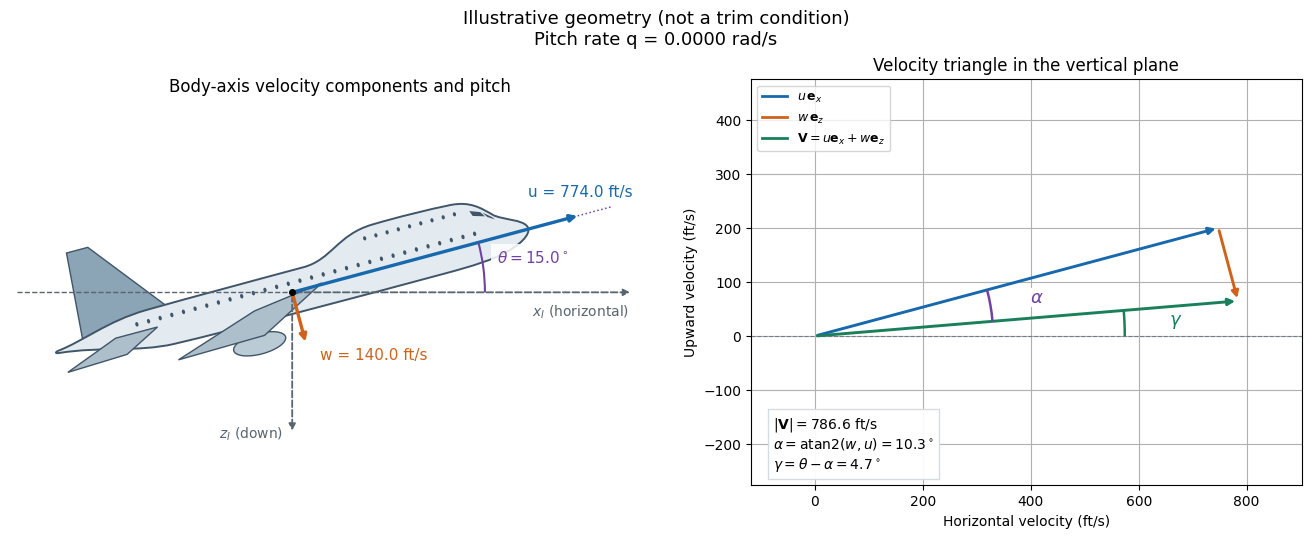

In [4]:
# Supplied geometry illustration; edit u, w, and theta to explore the arrows.
x_example = np.array([774.0, 140.0, 0.0, np.deg2rad(15.0)])
fig, axes = plot_longitudinal_state(
    x_example, title="Illustrative geometry (not a trim condition)"
)
plt.show()

### Velocity geometry

The total velocity and airspeed are

$$
\mathbf V=u\mathbf e_x+w\mathbf e_z,\qquad V=\sqrt{u^2+w^2}.
$$

Resolving this velocity into horizontal and upward components gives

$$
\begin{aligned}
V_{\mathrm{horizontal}}&=u\cos\theta+w\sin\theta,\\
V_{\mathrm{upward}}&=u\sin\theta-w\cos\theta.
\end{aligned}
$$

The upward velocity component is positive opposite to the inertial $z_I$ direction shown in the diagram.

For forward flight ($u>0$), define $\alpha$ as the angle from the velocity direction to the aircraft's forward reference axis, and $\gamma$ as the flight-path angle above the horizontal. Then

$$
\alpha=\operatorname{atan2}(w,u),\qquad \gamma=\theta-\alpha.
$$

The pitch angle $\theta$ specifies the aircraft's orientation; the flight-path angle $\gamma$ specifies its direction of travel. The quantity $\alpha$ measures their difference using the model's reference axis.

*The diagram is a supplied illustration with exaggerated angles for clarity. It depicts an arbitrary state rather than steady level flight. The plotting helper takes an absolute state $[u,w,q,\theta]$ with angles in radians; displayed angles are converted to degrees.*


### Control Inputs

The longitudinal dynamics are controlled by two inputs. The elevator is located along the trailing edge of the horizontal tail. Elevator deflection changes the aerodynamic force on the horizontal tail, producing a pitching moment about the center of gravity. Engine throttle adjusts the total thrust.
These are denoted by $\delta_e$ and $\delta_t$, respectively, with $\delta_e$ measured in radians and $\delta_t$ dimensionless.

Since $u$ already denotes the forward velocity component, we denote the control vector by $\eta$:
$$ \eta = \begin{bmatrix} \delta_e & \delta_t \end{bmatrix}^T. $$


## Equilibrium for steady level flight

We take steady level flight at the constant forward speed $U_0=774\ \mathrm{ft/s}$ as the reference condition.
The flight-path angle and pitch rate are zero. With the forward axis aligned with the reference velocity, the equilibrium state is

$$
x^*=\begin{bmatrix}U_0&0&0&0\end{bmatrix}^{T}.
$$

Here $w^*=0$ and $\theta^*=0$ imply $\alpha^*=0$ and $\gamma^*=0$ in the model's reference-axis convention.
The aircraft continues moving horizontally at $U_0$ while its four modeled state variables remain constant.

In this model, elevator and throttle inputs are measured relative to their steady level-flight values. Therefore,

$$ \eta^*=\begin{bmatrix} 0 & 0 \end{bmatrix}^T. $$


In [5]:
U0 = 774.0
x_trim = np.array([U0, 0., 0., 0.])
print("Steady level-flight equilibrium:", x_trim)

Steady level-flight equilibrium: [774.   0.   0.   0.]


## Nonlinear equations of motion

The nonlinear equations $\dot x=f(x,\eta)$ are

$$
\begin{aligned}
\dot u &= \frac{X_u(u-U_0)+X_w w+X_\eta\eta}{m}-qw-g\sin\theta,\\
\dot w &= \frac{Z_u(u-U_0)+Z_w w+Z_q q+Z_\eta\eta+mqu+mg(\cos\theta-1)}{m-Z_{\dot w}},\\
\dot q &= \frac{M_u(u-U_0)+M_w w+M_q q+M_{\dot w}\dot w+M_\eta\eta}{I_y},\\
\dot\theta &=q.
\end{aligned}
$$

Here $m$ is mass, $I_y$ is pitch inertia, and $g$ is gravitational acceleration.
The $X$, $Z$, and $M$ coefficients describe local axial-force, normal-force, and pitching-moment derivatives; $X_\eta$, $Z_\eta$, and $M_\eta$ are two-entry rows multiplying the control increments.
The coefficients $Z_{\dot w}$ and $M_{\dot w}$ are the normal-force and pitching-moment derivatives with respect to $\dot w$. In the code, `Xdelta`, `Zdelta`, and `Mdelta` correspond to $X_\eta$, $Z_\eta$, and $M_\eta$, respectively, with the elevator entry first and the throttle entry second.

At the reference state and input, $u-U_0$, $w$, $q$, $\sin\theta$, and $\cos\theta-1$ all vanish, so

$$
f(x^*,\eta^*)=0.
$$

All coefficients and the right-hand-side function are supplied below; you do not need to derive aircraft force or moment coefficients.

In [6]:
g = 32.2
m = 636636.0 / g
cbar = 27.31
Iy = 0.331e8
Xu, Xw = -1.358e2, 2.758e2
Zu, Zw, Zq, Zwdot = -1.778e3, -6.188e3, -1.017e5, 1.308e2
Mwdot = -3.826e3
Xdelta = np.array([-3.717, 0.3*g*m])
Zdelta = np.array([-3.551e5, 0.0])
Mdelta = np.array([-3.839e7, 0.0])
# Recover local moment derivatives from the lecture's rounded third row.
lecture_pitch_row = np.array([0.0001187, -0.001026, -0.4285])
w_dot_derivatives = np.array([Zu, Zw, Zq+m*U0])/(m-Zwdot)
Mu, Mw, Mq = Iy*lecture_pitch_row - Mwdot*w_dot_derivatives

def nonlinear_rhs(t, x, eta):
    """Absolute state [u, w, q, theta]; input increments [elevator, throttle]."""
    u, w, q, theta = x
    du = u-U0
    u_dot = (Xu*du+Xw*w+Xdelta@eta)/m - q*w - g*np.sin(theta)
    w_dot = (Zu*du+Zw*w+Zq*q+Zdelta@eta
             +m*q*u-2*m*g*np.sin(theta/2)**2)/(m-Zwdot)
    q_dot = (Mu*du+Mw*w+Mq*q+Mwdot*w_dot+Mdelta@eta)/Iy
    return np.array([u_dot, w_dot, q_dot, q])

## Linearized equations about steady level flight

Define the state perturbation from the equilibrium by
$$
\Delta x=x-x^*=\begin{bmatrix}\Delta u&\Delta w&\Delta q&\Delta\theta\end{bmatrix}^{T}.
$$

Because $\eta$ already measures the control increment from trim, we have
$$
\Delta \eta = \eta - \eta^* = \eta. 
$$

Retaining first-order terms in the state and control perturbations about steady level flight gives the linearized equations of motion:
$$
\begin{aligned}
\Delta\dot u &= \frac{X_u}{m}\Delta u+\frac{X_w}{m}\Delta w-g\Delta\theta+\frac{X_\eta}{m}\eta,\\
\Delta\dot w &= \frac{Z_u\Delta u+Z_w\Delta w+(Z_q+mU_0)\Delta q+Z_\eta\eta}{m-Z_{\dot w}},\\
\Delta\dot q &= \frac{M_u\Delta u+M_w\Delta w+M_q\Delta q+M_{\dot w}\Delta\dot w+M_\eta\eta}{I_y},\\
\Delta\dot\theta &=\Delta q,
\end{aligned}
$$
Substituting the expression for $\Delta\dot w$ into the pitch-rate equation gives the state-space form
$$
\Delta\dot x=A\Delta x+B\eta. 
$$

The matrices are the Jacobians evaluated at equilibrium:
$$
A=\left.\frac{\partial f}{\partial x}\right|_{(x^*,0)},\qquad
B=\left.\frac{\partial f}{\partial\eta}\right|_{(x^*,0)}.
$$

These are implemented as follows.
The linear right-hand-side function takes a **perturbation state** $\Delta x$; the nonlinear function takes an **absolute state** $x$.
Subtract `x_trim` from the nonlinear solution before comparing it with the linear solution.
To visualize a nonlinear simulation, pass a column of its absolute-state solution to `plot_longitudinal_state`.
For a linear simulation, add `x_trim` to the perturbation state first.

In [ ]:
A = np.array([
    [Xu/m, Xw/m, 0., -g],
    [Zu/(m-Zwdot), Zw/(m-Zwdot), (Zq+m*U0)/(m-Zwdot), 0.],
    [0.0001187, -0.001026, -0.4285, 0.],
    [0., 0., 1., 0.],
])
B = np.vstack([Xdelta/m, Zdelta/(m-Zwdot),
               (Mdelta+Mwdot*Zdelta/(m-Zwdot))/Iy, np.zeros(2)])

def linear_rhs(t, dx, eta):
    return A@dx+B@eta

def central_jacobian(fun, point, steps):
    """Central differences with a separate step for each coordinate."""
    eye = np.eye(len(point))
    return np.column_stack([(fun(point+h*e)-fun(point-h*e))/(2*h)
                            for e,h in zip(eye, steps)])

In [8]:
print("A =\n", A)
print("B =\n", B)

A =
 [[ -0.006869   0.01395    0.       -32.2     ]
 [ -0.090527  -0.315063 773.976538   0.      ]
 [  0.000119  -0.001026  -0.4285     0.      ]
 [  0.         0.         1.         0.      ]]
B =
 [[ -0.000188   9.66    ]
 [-18.079984   0.      ]
 [ -1.157729   0.      ]
 [  0.         0.      ]]


## 1. Nonlinear and linear simulation consistency (25 points)

Hold the controls at trim: $\eta(t)=0$.
Use `solve_ivp` with `rtol=1e-10` and `atol=1e-12` for both models and evaluate both solutions on the same time grid.
Check the solver's success flag before using its output.

**(a) Trim and Jacobian checks — 5 points.**
Evaluate $f(x^*,0)$.
Use the supplied `central_jacobian` function to approximate $\partial f/\partial x$ and $\partial f/\partial\eta$ at trim.
Use state steps $[10^{-3},10^{-3},10^{-6},10^{-6}]$ and input steps $[10^{-6},10^{-6}]$.
Report the largest absolute entrywise differences from $A$ and $B$, and explain what these checks establish.

**(b) Simulation and plots — 12 points.**
As each component of the state vector $\Delta x$ has different physical unit,
we define the dimensionless perturbation $z=S^{-1}\Delta x$, with

$$
S=\operatorname{diag}\!\left(U_0,U_0,\frac{2U_0}{\bar c},1\right),\qquad \bar c=27.31\ \mathrm{ft},
$$
where $\bar c$ is the mean chord length.

For each $\varepsilon\in\{0.01,0.05,0.1\}$, use

$$
z(0)=\varepsilon\begin{bmatrix}1&0&0&1\end{bmatrix}^{T}.
$$

Initialize the nonlinear model at $x^*+Sz(0)$ and the linear model at $Sz(0)$.
Simulate from 0 to 300 s with 3001 equally spaced output times.
For comparison, define the normalized nonlinear and linear responses by

$$
z_{\mathrm{NL}}(t)=S^{-1}\bigl(x_{\mathrm{NL}}(t)-x^*\bigr),\qquad
z_{\mathrm{L}}(t)=S^{-1}\Delta x_{\mathrm{L}}(t).
$$

Here $x_{\mathrm{NL}}$ is the absolute nonlinear state and $\Delta x_{\mathrm{L}}$ is the linear perturbation state; these normalized responses are `z_nl` and `z_lin` in the code.
For each perturbation size, overlay all four components of $z_{\mathrm{NL}}$ and $z_{\mathrm{L}}$ in four labeled panels.
Remember to subtract $x^*$ from the nonlinear solution before comparing perturbations.

**(c) Error and interpretation — 8 points.**
For each simulation, calculate

$$
E(\varepsilon)=\max_{t\in\text{output grid}}\left\|z_{\mathrm{NL}}(t)-z_{\mathrm{L}}(t)\right\|_2.
$$

Report $E(0.05)/E(0.01)$.
Explain the trend as the perturbation decreases and relate it to the terms neglected by linearization.
Does close agreement here establish that the models predict the real aircraft accurately far from trim?

In [ ]:
# 1(a): Check trim and both numerical Jacobians.
eta_zero = np.zeros(2)
x_steps = np.array([1e-3, 1e-3, 1e-6, 1e-6])
eta_steps = np.array([1e-6, 1e-6])

# Your code here.


In [ ]:
# 1(b): Simulate and plot the nonlinear and linear responses.
# Supplied state scaling: delta_x = S @ z and z = S_inv @ delta_x.
scales = np.array([U0, U0, 2*U0/cbar, 1.])
S = np.diag(scales)
S_inv = np.diag(1/scales)

t_eval = np.linspace(0.0, 300.0, 3001)
eps_values = [0.01, 0.05, 0.1]
state_labels = [r"$\Delta u/U_0$", r"$\Delta w/U_0$",
                r"$\Delta q/(2U_0/\bar c)$", r"$\Delta\theta$"]

# Your code here.


In [ ]:
# 1(c): Compute the normalized errors and their ratio, and interpret the results.
# Your code here.


**Answer 1:**

_Write your interpretation here._

## 2. Eigenpairs and longitudinal modes (15 points)

Consider the linearized system with the controls held at trim, $\Delta\dot x=A\Delta x$.

**(a) Eigenvalues and eigenvectors — 4 points.**
Use `np.linalg.eig` to find the four eigenvalues of $A$ and their corresponding right eigenvectors.
Report each eigenvalue together with its corresponding eigenvector. The eigenvectors are returned as columns of the eigenvector matrix; keep each column paired with its eigenvalue.

**(b) Identify the longitudinal modes — 4 points.**
The eigenvalues form two complex-conjugate pairs, each describing an oscillatory mode.
The **phugoid mode** involves gradual changes in forward speed and flight-path motion.
The **short-period mode** involves more rapid changes in angle of attack and pitch motion.

Choose one representative from each conjugate pair: the eigenvalue with positive imaginary part and its corresponding eigenvector.
For an eigenvalue $\lambda=\sigma+i\omega_d$, the oscillation envelope varies as $e^{\sigma t}$; for stable modes, a more negative $\sigma$ means faster decay.
For the supplied model, identify the modes by their decay rates and assign the representative eigenpairs to the following variables:

- `lam_short`, `v_short`: the eigenvalue and eigenvector of the mode with faster decay.
- `lam_phugoid`, `v_phugoid`: the eigenvalue and eigenvector of the mode with slower decay.

Report both assigned eigenpairs. Use the eigenvalue real parts to distinguish their decay rates; do not assume a particular order in the eigensolver output.

**(c) Compare the modes — 7 points.**
For each selected eigenvalue $\lambda=\sigma+i\omega_d$, report its real part $\sigma$, angular oscillation frequency $\omega_d$, period $T$, and decay time constant $\tau$, using

$$
T=\frac{2\pi}{\omega_d},\qquad
\tau=-\frac{1}{\sigma}\quad(\sigma<0).
$$

The decay time constant is the time for the oscillation envelope to fall to $1/e$ of its initial value.
Compare the phugoid and short-period modes in terms of stability, oscillation speed, and decay time. Distinguish the role of the eigenvalue real part from that of its imaginary part, and support your comparison with numerical values and appropriate units.
Assuming both modes are initially excited, which mode is most likely to remain visible after the other transient has decayed? Explain your answer.


In [ ]:
# 2(a): Compute and report the eigenvalues and corresponding right eigenvectors.
# Your code here.


In [ ]:
# 2(b): Identify the modes and assign lam_short, v_short,
# lam_phugoid, and v_phugoid as requested.
# Your code here.


In [ ]:
# 2(c): Compute and compare the mode characteristics.
# Your code here.


**Answer 2:**

**(a)** _Write your answer here._

**(b)** _Write your answer here._

**(c)** _Write your answer here._


## 3. Phugoid eigenvector and mode shape (15 points)

Use the phugoid eigenpair `lam_phugoid`, `v_phugoid` of $A$ from Question 2.
The components of a dimensional eigenvector correspond to states with different units, so their raw magnitudes cannot be compared directly. First express the eigenvector in the dimensionless coordinates $z=S^{-1}\Delta x$ from Question 1:

$$
v_{\mathrm{phugoid},z}=S^{-1}v_{\mathrm{phugoid}},\qquad
A_z=S^{-1}AS,\qquad B_z=S^{-1}B.
$$

An eigenvector may also be multiplied by any nonzero complex scalar without changing the mode it represents. To fix this arbitrary magnitude and phase, use the pitch-angle component as the reference:

$$
\widehat v_{\mathrm{phugoid}}
=\frac{v_{\mathrm{phugoid},z}}{(v_{\mathrm{phugoid},z})_\theta}
=\begin{bmatrix}\widehat v_u&\widehat v_w&\widehat v_q&1\end{bmatrix}^{T}.
$$

The fourth component is now $1+0i$. The other components describe the relative magnitudes and phases of the normalized states $\Delta u/U_0$, $\Delta w/U_0$, and $\Delta q/(2U_0/\bar c)$ with respect to $\Delta\theta$.
Divide by the complex pitch-angle component itself, not by its magnitude; this sets both the reference magnitude and reference phase.

**(a) Normalize the eigenvector — 4 points.**
Compute $\widehat v_{\mathrm{phugoid}}$ and store it as `v_phugoid_hat`. Check that the pitch-angle component is nonzero before dividing.
Print its four complex components, labeling each with the corresponding normalized state. Confirm that the fourth component is $1+0i$.

**(b) Visualize the components — 7 points.**
Plot all four components of $\widehat v_{\mathrm{phugoid}}$ as labeled arrows from the origin in the complex plane. Use equal scales on the real and imaginary axes.

Also generate a table listing the magnitude and phase of each component. For a component $\widehat v_j=a_j+ib_j$, use

$$
|\widehat v_j|=\sqrt{a_j^2+b_j^2},\qquad
\phi_j=\operatorname{atan2}(b_j,a_j),\qquad
\phi_{j,\mathrm{deg}}=\frac{180}{\pi}\phi_j.
$$

You may use `np.abs` and `np.angle(..., deg=True)`. Report phases in degrees relative to the pitch-angle component, whose magnitude is 1 and phase is $0^\circ$. The phase of an exactly zero component is undefined.

**(c) Dominant state for the phugoid mode — 4 points.**

From your answers to (b), identify two state variables dorminant in the phugoid mode, and describe the relative phase between them. 

In [ ]:
# 3(a): Normalize the phugoid eigenvector and print its components.
# Supplied dynamics in normalized state coordinates.
A_z = S_inv @ A @ S
B_z = S_inv @ B

# Your code here.


In [ ]:
# 3(b): Plot the complex-plane arrows and tabulate magnitudes and phases.
# Your code here.


In [ ]:
# 3(c): Identify the dominant normalized components and their relative phase.
# Your code here.


**Answer 3:**

**(a)** _Write your answer here._

**(b)** _Write your answer here._

**(c)** _Write your answer here._


## 4. Phugoid time response (20 points)

Consider the free response of the linearized system with the controls held at trim:

$$
\dot z=A_z z,\qquad \eta(t)=0.
$$

Use the following real initial condition, constructed from the normalized phugoid eigenvector in Question 3:

$$
z(0)=a\,\mathrm{Re}\!\left(\widehat v_{\mathrm{phugoid}}\right),\qquad a=0.01.
$$

This initial condition lies in the real subspace of the phugoid conjugate pair and therefore excites only the phugoid mode in the linearized model.
In dimensional perturbation coordinates, the same initial condition is $\Delta x(0)=Sz(0)$.

**(a) Simulate and plot the response — 5 points.**
Use `solve_ivp` to simulate $\dot z=A_z z$ from 0 to 300 s with 3001 equally spaced output times, `rtol=1e-10`, and `atol=1e-12`. Check the solver's success flag before using its output.
Plot all four normalized state components together on a single set of axes as functions of time. Include a legend identifying each component, label the time axis in seconds, and label the vertical axis as normalized perturbation.

**(b) Interpret the response — 6 points.**
Explain how the response in part (a) is consistent with the phugoid eigenvalue from Question 2 and the normalized eigenvector from Question 3.

- Use the real and imaginary parts of `lam_phugoid` to explain the stability, decay time, and oscillation period seen in the plot.
- Use the component magnitudes and phases of `v_phugoid_hat` to explain the relative oscillation envelopes and timing of the four state responses. Compare the forward-speed component with pitch angle, stating which leads and by approximately how many degrees.

Support your discussion with numerical values from Questions 2 and 3 and features visible in your plot.

**(c) Research and physical interpretation — 9 points.**
Using at least two reliable sources, such as flight-dynamics textbooks, university lecture notes, or NASA publications, address the following topics. Connect each topic to the simulation plot discussed in part (b).

1. **Physical mechanism and energy exchange.** Explain how changes in airspeed and altitude exchange kinetic and gravitational potential energy during a phugoid oscillation. Describe the sequence of acceleration, climb, deceleration, and descent. Distinguish quantities directly shown in the plot from altitude changes inferred from the motion.
2. **Approximate oscillation period.** Find a classical approximate expression relating the phugoid period to trim airspeed and gravitational acceleration. State its assumptions, evaluate it using the supplied parameters, and compare it with the period obtained from the eigenvalue and observed in the plot. Explain why the values need not agree exactly.
3. **Damping and persistence.** Research the physical factors that influence phugoid damping. Relate them to the gradual decay seen in the plot, and briefly discuss why a persistent phugoid matters for maintaining airspeed and altitude.

Cite your sources and support your discussion with specific features or numerical results from the simulation. No additional plots are required.


In [ ]:
# 4(a): Simulate and plot the response for the prescribed initial condition.
# Your code here.


In [ ]:
# 4(c): Numerical calculations supporting your research discussion.
# Your code here.


**Answer 4:**

**(a)** _Write your answer here._

**(b)** _Write your answer here._

**(c)** _Write your answer here._


## 5. Observability and sensor selection (25 points)

Assume the input history is known and there is no direct feedthrough.
Consider the following ideal sensor choices, expressed in normalized coordinates:

| Sensor | Measurement | Measurement matrix in $y=Cz$ |
|---|---|---|
| Forward-speed sensor | $\Delta u/U_0$ | $C_u=[1\ 0\ 0\ 0]$ |
| Pitch-rate gyro | $\Delta q/(2U_0/\bar c)$ | $C_q=[0\ 0\ 1\ 0]$ |
| Pitch-attitude sensor | $\Delta\theta$ | $C_\theta=[0\ 0\ 0\ 1]$ |

Use the normalized dynamics $\dot z=A_z z+B_z\eta$ throughout this problem.
Multiplying a physical sensor output by a known nonzero scale does not change exact observability.

**(a) Observability of each sensor — 6 points.**
Determine whether each sensor, used alone, makes the complete four-state linear model observable.
For each $C_i\in\{C_u,C_q,C_\theta\}$, form

$$
\mathcal O_i=\begin{bmatrix}C_i\\C_iA_z\\C_iA_z^2\\C_iA_z^3\end{bmatrix}.
$$

Report its singular values and numerical rank using `np.linalg.matrix_rank` with its default tolerance.
Also report the corresponding tolerance $\max(m,n)\epsilon_{\rm mach}s_{\max}$, where $(m,n)$ is the shape of $\mathcal O_i$.
Support each observability conclusion with your results.

**(b) Research on sensor quality — 9 points.**
Research how the pair $(A,C)$ can be used to assess the quality, or “goodness,” of a sensor for reconstructing the state.
Explain why observability rank alone does not distinguish how well different observable sensor choices allow state reconstruction.
Identify at least one quantitative measure beyond rank, give its mathematical definition, and explain whether a larger or smaller value indicates better performance and why.
Discuss how state and output scaling, measurement noise, and, where applicable, the observation interval affect the interpretation of the measure.
Cite the sources you use and select a measure to apply to $(A_z,C)$ in part (c).

**(c) Selecting two sensors — 10 points.**
Suppose only two of the three sensors can be used.
Compare all three combinations using

$$
C_{u,q}=\begin{bmatrix}C_u\\C_q\end{bmatrix},\qquad
C_{u,\theta}=\begin{bmatrix}C_u\\C_\theta\end{bmatrix},\qquad
C_{q,\theta}=\begin{bmatrix}C_q\\C_\theta\end{bmatrix}.
$$

Apply the measure selected in part (b) to each pair and report the results in a table.
Use the same state scaling and consistent measurement-noise assumptions for all three combinations; if your measure depends on an observation interval or sampling rate, use the same values for all combinations.
State these assumptions explicitly.
Identify the best pair under your chosen measure and assumptions, and explain why your numerical results support that choice.


In [ ]:
# 5(a): Observability of each sensor.
C_u = np.array([[1., 0., 0., 0.]])
C_q = np.array([[0., 0., 1., 0.]])
C_theta = np.array([[0., 0., 0., 1.]])

# Form each observability matrix and report singular values, rank, and tolerance.
# Your code here.


In [ ]:
# 5(c): Compare all three sensor pairs using your measure from part (b).
C_uq = np.vstack([C_u, C_q])
C_utheta = np.vstack([C_u, C_theta])
C_qtheta = np.vstack([C_q, C_theta])

# State your comparison assumptions and report the results in a table.
# Your code here.


**Answer 5:**

**(a)** _Write your answer here._

**(b)** _Write your answer here._

**(c)** _Write your answer here._
